In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as  plt
from sklearn.preprocessing import StandardScaler, LabelEncoder,OneHotEncoder
from sklearn.model_selection import train_test_split

In [2]:
rb = pd.read_csv('DataSet.csv')

In [3]:
rb

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,31-12-2012,springer,2012,12,19,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,11,108,119
17375,17376,31-12-2012,springer,2012,12,20,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,8,81,89
17376,17377,31-12-2012,springer,2012,12,21,No,1,Working Day,Clear,?,0.2576,0.6,0.1642,7,83,90
17377,17378,31-12-2012,springer,2012,12,22,No,1,Working Day,Clear,0.26,0.2727,0.56,0.1343,13,48,61


In [4]:
rb.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   instant     17379 non-null  int64
 1   dteday      17379 non-null  str  
 2   season      17379 non-null  str  
 3   yr          17379 non-null  str  
 4   mnth        17379 non-null  str  
 5   hr          17379 non-null  int64
 6   holiday     17379 non-null  str  
 7   weekday     17379 non-null  int64
 8   workingday  17379 non-null  str  
 9   weathersit  17379 non-null  str  
 10  temp        17379 non-null  str  
 11  atemp       17379 non-null  str  
 12  hum         17379 non-null  str  
 13  windspeed   17379 non-null  str  
 14  casual      17379 non-null  str  
 15  registered  17379 non-null  str  
 16  cnt         17379 non-null  int64
dtypes: int64(4), str(13)
memory usage: 3.3 MB


In [5]:
rb.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [6]:
rb['dteday'] = pd.to_datetime(rb['dteday'], format = '%d-%m-%Y')

In [7]:
rb['season'].unique()

<ArrowStringArray>
['springer', '?', 'summer', 'fall', 'winter']
Length: 5, dtype: str

In [8]:
rb.duplicated().sum()

np.int64(0)

In [9]:
rb.replace('?', np.nan, inplace = True)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,2011-01-01,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,2011-01-01,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,NaN,0,5,27,32
3,4,2011-01-01,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,2011-01-01,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,springer,2012,12,19,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,11,108,119
17375,17376,2012-12-31,springer,2012,12,20,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,8,81,89
17376,17377,2012-12-31,springer,2012,12,21,No,1,Working Day,Clear,NaN,0.2576,0.6,0.1642,7,83,90
17377,17378,2012-12-31,springer,2012,12,22,No,1,Working Day,Clear,0.26,0.2727,0.56,0.1343,13,48,61


In [10]:
rb['holiday'].value_counts()

holiday
No     16878
Yes      500
Name: count, dtype: int64

In [11]:
numeric_col = ['temp','atemp','hum','windspeed','casual','registered']
for col in numeric_col :
    rb[col]=pd.to_numeric(rb[col], errors = 'coerce')

In [12]:
rb.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17373 non-null  str           
 3   yr          17378 non-null  str           
 4   mnth        17378 non-null  str           
 5   hr          17379 non-null  int64         
 6   holiday     17378 non-null  str           
 7   weekday     17379 non-null  int64         
 8   workingday  17374 non-null  str           
 9   weathersit  17375 non-null  str           
 10  temp        17368 non-null  float64       
 11  atemp       17373 non-null  float64       
 12  hum         17373 non-null  float64       
 13  windspeed   17374 non-null  float64       
 14  casual      17378 non-null  float64       
 15  registered  17378 non-null  float64       
 16  cnt         17379 non-null  int64

In [13]:
rb.drop(columns = ['instant'])


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,2011-01-01,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0.0000,3.0,13.0,16
1,2011-01-01,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.80,0.0000,8.0,32.0,40
2,2011-01-01,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,NaN,0.0000,5.0,27.0,32
3,2011-01-01,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0.0000,3.0,10.0,13
4,2011-01-01,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0.0000,0.0,1.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,2012-12-31,springer,2012,12,19,No,1,Working Day,Mist,0.26,0.2576,0.60,0.1642,11.0,108.0,119
17375,2012-12-31,springer,2012,12,20,No,1,Working Day,Mist,0.26,0.2576,0.60,0.1642,8.0,81.0,89
17376,2012-12-31,springer,2012,12,21,No,1,Working Day,Clear,NaN,0.2576,0.60,0.1642,7.0,83.0,90
17377,2012-12-31,springer,2012,12,22,No,1,Working Day,Clear,0.26,0.2727,0.56,0.1343,13.0,48.0,61


In [14]:
rb.isnull().sum()

instant        0
dteday         0
season         6
yr             1
mnth           1
hr             0
holiday        1
weekday        0
workingday     5
weathersit     4
temp          11
atemp          6
hum            6
windspeed      5
casual         1
registered     1
cnt            0
dtype: int64

In [15]:
rb.dropna(inplace = True)

In [16]:
rb.duplicated().sum()

np.int64(0)

In [17]:
rb['season'] = rb['season'].replace({
    'springer':'spring'
})

In [18]:
rb['season'].unique()


<ArrowStringArray>
['spring', 'summer', 'fall', 'winter']
Length: 4, dtype: str

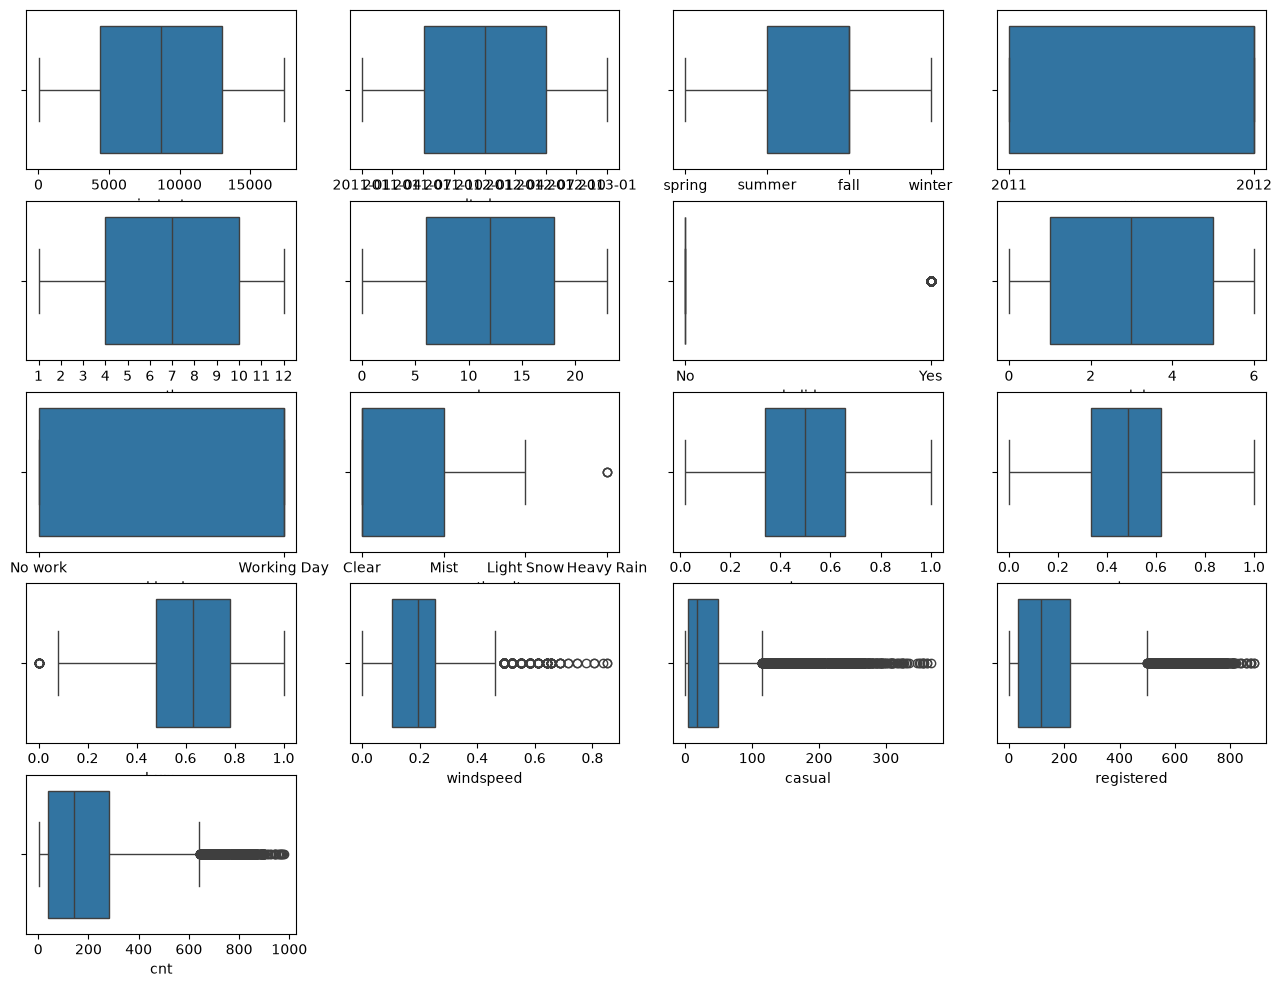

In [19]:
plt.figure(figsize=(16,12))
for i ,col in enumerate(rb, 1):
    plt.subplot(5,4,i)
    sns.boxplot(x = rb[col])
    # plt.title(f'Boxplot of {rb[col]}')

plt.show()


<Axes: >

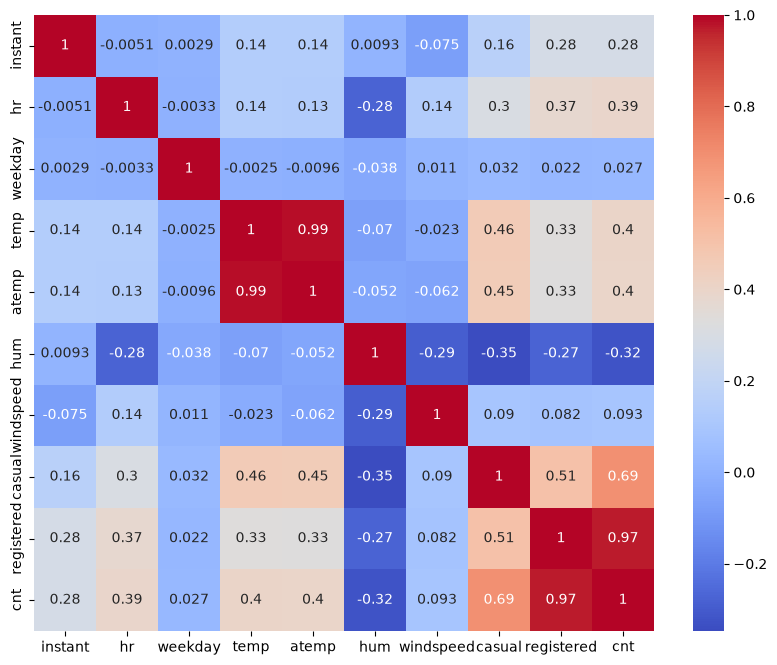

In [20]:
plt.figure(figsize= (10,8))
sns.heatmap(rb.corr(numeric_only = True), annot = True, cmap='coolwarm')

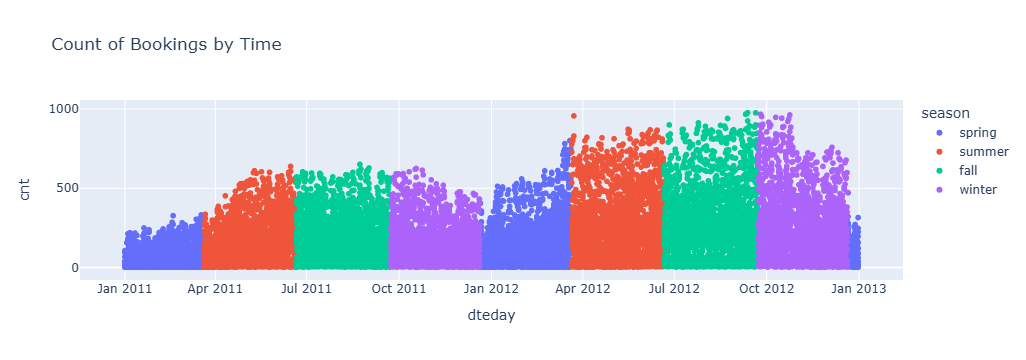

In [21]:
import plotly.express as px

fig = px.scatter(rb, x = 'dteday', y='cnt',
                 hover_data=['season','holiday','weekday','weathersit',],
                 color = 'season',
                 title = 'Count of Bookings by Time')
fig.update_traces(
    hovertemplate = (
        'Date: %{x}<br>'
        'Count:%{y}<br>'
        'season: %{customdata[0]}<br>'
        'holiday: %{customdata[1]}<br>'
        'weekday:%{customdata[2]}<br>'
        'weathersit:%{customdata[3]}<extra></extra>')

)
fig.show()

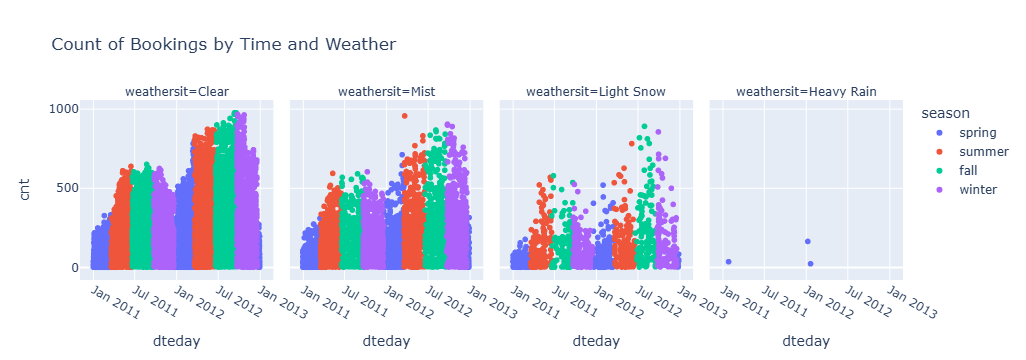

In [22]:
import plotly.express as px

# Create separate columns of plots for each weather situation
fig = px.scatter(
    rb, 
    x='dteday', 
    y='cnt', 
    color='season', 
    facet_col='weathersit',  # Creates a separate subplot for each weather type (Clear, Mist, Rain, etc.)
    title='Count of Bookings by Time and Weather'
)

fig.show()

In [23]:
# df.to_csv('rb.csv', index = False)
import pandas as pd

# Export to the same folder as your notebook
rb.to_csv('rb.csv', index=False)

In [24]:
rb['weathersit'].unique(),rb['weathersit'].value_counts()

(<ArrowStringArray>
 ['Clear', 'Mist', 'Light Snow', 'Heavy Rain']
 Length: 4, dtype: str,
 weathersit
 Clear         11400
 Mist           4522
 Light Snow     1414
 Heavy Rain        3
 Name: count, dtype: int64)

In [25]:
rb['workingday'].unique()

<ArrowStringArray>
['No work', 'Working Day']
Length: 2, dtype: str

In [26]:
rb['holiday'] = rb['holiday'].map({'Yes':1,'No':0})
rb['workingday'] = rb['workingday'].map({'No work' :0, 'Working Day': 1 })

In [27]:
rb = pd.get_dummies(rb,columns = ['season'], drop_first = True)

In [28]:
rb = pd.get_dummies(rb, columns = ['weathersit'], drop_first = True)

In [29]:
rb['temp_diff'] = rb['atemp'] - rb['temp'] #temp - feeling temparature
rb['is_rush_hour'] = rb['hr'].isin([7, 8, 9, 17, 18, 19]).astype(int) #rushhours feature

In [30]:
rb

,instant,dteday,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,...,registered,cnt,season_spring,season_summer,season_winter,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist,temp_diff,is_rush_hour
0,1,2011-01-01,2011,1,0,0,6,0,0.24,0.2879,...,13.0,16,True,False,False,False,False,False,0.0479,0
1,2,2011-01-01,2011,1,1,0,6,0,0.22,0.2727,...,32.0,40,True,False,False,False,False,False,0.0527,0
3,4,2011-01-01,2011,1,3,0,6,0,0.24,0.2879,...,10.0,13,True,False,False,False,False,False,0.0479,0
4,5,2011-01-01,2011,1,4,0,6,0,0.24,0.2879,...,1.0,1,True,False,False,False,False,False,0.0479,0
5,6,2011-01-01,2011,1,5,0,6,0,0.24,0.2576,...,1.0,1,True,False,False,False,False,True,0.0176,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17370,17371,2012-12-31,2012,12,15,0,1,1,0.28,0.2879,...,246.0,315,True,False,False,False,False,True,0.0079,0
17373,17374,2012-12-31,2012,12,18,0,1,1,0.26,0.2727,...,112.0,122,True,False,False,False,False,True,0.0127,1
17374,17375,2012-12-31,2012,12,19,0,1,1,0.26,0.2576,...,108.0,119,True,False,False,False,False,True,-0.0024,1
17375,17376,2012-12-31,2012,12,20,0,1,1,0.26,0.2576,...,81.0,89,True,False,False,False,False,True,-0.0024,0


# Train Test Split

In [31]:
X = rb.drop(columns = ['casual','registered','cnt','dteday','instant'])
y = rb['cnt']

In [46]:
ss = StandardScaler()

x_scaler = ss.fit_transform(X)

In [47]:
x_scaler = pd.DataFrame(x_scaler, columns = X.columns, index = X.index)

In [50]:
X.head(5)

,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,hum,windspeed,season_spring,season_summer,season_winter,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist,temp_diff,is_rush_hour
0,2011,1,0,0,6,0,0.24,0.2879,0.81,0.0000,True,False,False,False,False,False,0.0479,0
1,2011,1,1,0,6,0,0.22,0.2727,0.80,0.0000,True,False,False,False,False,False,0.0527,0
3,2011,1,3,0,6,0,0.24,0.2879,0.75,0.0000,True,False,False,False,False,False,0.0479,0
4,2011,1,4,0,6,0,0.24,0.2879,0.75,0.0000,True,False,False,False,False,False,0.0479,0
5,2011,1,5,0,6,0,0.24,0.2576,0.75,0.0896,True,False,False,False,False,True,0.0176,0


In [49]:
x_scaler.head(5)

,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,hum,windspeed,season_spring,season_summer,season_winter,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist,temp_diff,is_rush_hour
0,-1.004683,-1.612614,-1.669392,-0.171249,1.494051,-1.468133,-1.338364,-1.096937,0.947469,-1.554187,1.768154,-0.583943,-0.568226,-0.013155,-0.297979,-0.593980,1.960374,-0.579326
1,-1.004683,-1.612614,-1.524792,-0.171249,1.494051,-1.468133,-1.442304,-1.185455,0.895652,-1.554187,1.768154,-0.583943,-0.568226,-0.013155,-0.297979,-0.593980,2.096424,-0.579326
3,-1.004683,-1.612614,-1.235592,-0.171249,1.494051,-1.468133,-1.338364,-1.096937,0.636568,-1.554187,1.768154,-0.583943,-0.568226,-0.013155,-0.297979,-0.593980,1.960374,-0.579326
4,-1.004683,-1.612614,-1.090992,-0.171249,1.494051,-1.468133,-1.338364,-1.096937,0.636568,-1.554187,1.768154,-0.583943,-0.568226,-0.013155,-0.297979,-0.593980,1.960374,-0.579326
5,-1.004683,-1.612614,-0.946392,-0.171249,1.494051,-1.468133,-1.338364,-1.273390,0.636568,-0.821553,1.768154,-0.583943,-0.568226,-0.013155,-0.297979,1.683557,1.101558,-0.579326


In [51]:
X_train, X_test, y_train, y_test = train_test_split(x_scaler, y, test_size = 0.2, random_state = 42)

In [52]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import ShuffleSplit, cross_validate
model = DecisionTreeRegressor()

In [53]:
shuffle = ShuffleSplit(n_splits = 400, test_size = 0.2,random_state = 42)
cross_v =cross_validate(
    estimator = model,
    X =  X_train, 
    y=y_train, 
    cv = shuffle, 
    scoring = ['neg_root_mean_squared_error','r2'],
    return_train_score = True
)

print(f'Mean test RMSE: {(-cross_v['test_neg_root_mean_squared_error']).mean():.4f}')
print(f'Mean Test R2 : {cross_v['test_r2'].mean():.4f}')

Mean test RMSE: 61.8706
Mean Test R2 : 0.8837


In [54]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state = 42,
    n_jobs = -1
)

rf_cross_v = cross_validate(
    estimator = rf_model,
    X = X_train,
    y= y_train,
    cv = shuffle,
    scoring = ['neg_root_mean_squared_error','r2'],
    return_train_score = True
)

In [55]:
# print(f'Mean Test RMSE: {(-rf_cross_v['test_neg_root_mean_squared_error']).mean():.4f}')
# print(f'R2 {rf_cross_v['test_r2'].mean():.4f}')

In [56]:
dt_train_rmse = (-cross_v ['train_neg_root_mean_squared_error']).mean()
dt_test_rmse = (-cross_v['test_neg_root_mean_squared_error']).mean()

dt_train_r2 = cross_v['train_r2'].mean()
dt_test_r2 = cross_v['test_r2'].mean()

print('---------------Decision Tree Performance---------------')
print(f'Decision Tree Train RMSE : {dt_train_rmse:.4f} | Decision Tree Test RMSE :{dt_test_rmse:.4f}')
print(f'Decision Tree Train R2 : {dt_train_r2:.4f} | Decision Tree Test R2 : {dt_test_r2:.4f}')

rf_train_rmse = (-rf_cross_v['train_neg_root_mean_squared_error']).mean()
rf_test_rmse = (-rf_cross_v['test_neg_root_mean_squared_error']).mean()

rf_train_r2 = rf_cross_v['train_r2'].mean()
rf_test_r2 = rf_cross_v['test_r2'].mean()


print('---------------Random Forest Performance---------------')
print(f'Random Forest Train RMSE : {rf_train_rmse:.4f} | Random Forest Test RMSE :{rf_test_rmse:.4f}')
print(f'Random Forest train R2 : {rf_train_r2:.4f} | Random Forest Test R2 : {rf_test_r2:.4f}')



---------------Decision Tree Performance---------------
Decision Tree Train RMSE : 0.2122 | Decision Tree Test RMSE :61.8706
Decision Tree Train R2 : 1.0000 | Decision Tree Test R2 : 0.8837
---------------Random Forest Performance---------------
Random Forest Train RMSE : 16.6346 | Random Forest Test RMSE :44.4076
Random Forest train R2 : 0.9916 | Random Forest Test R2 : 0.9401


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_176\2743438577.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


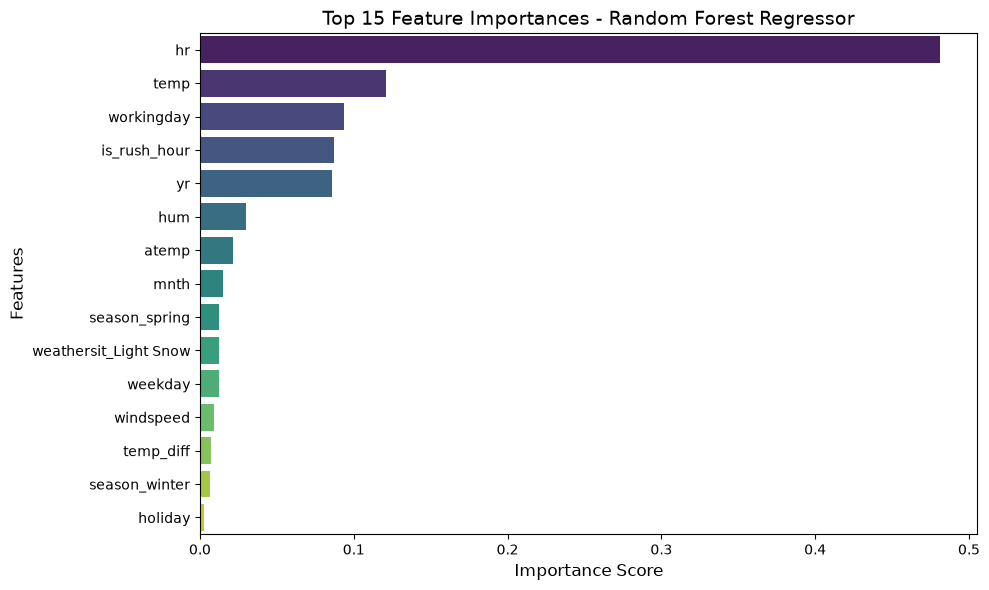

In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


rf_model.fit(X_train, y_train)

# 2. Extract feature importances and pair them with your feature column names
importances = rf_model.feature_importances_
feature_names = X_train.columns  # Ensure X_train is a pandas DataFrame

# 3. Create a DataFrame for easy sorting and plotting
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 4. Plot the top 15 most important features
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance_df.head(15), 
    x='Importance', 
    y='Feature', 
    palette='viridis'
)

plt.title('Top 15 Feature Importances - Random Forest Regressor', fontsize=14)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()